# 02 — Laser: equações de taxa e laser quase-monocromático

Este notebook segue a aula (`docs/04-class/context.md`) e o guia `docs/laser.md`. São dois
modelos de laser monomodo:

- **A. Equações de taxa** (modulação direta): a corrente injetada I(t) controla a densidade
  de portadores N(t) e a densidade de fótons S(t), o "fluxo de fótons" da aula.
- **B. Quase-monocromático** (modulação externa e oscilador local): laser em corrente
  constante, potência fixa e fase com ruído.

Regras usadas em todas as figuras (as mesmas do notebook da fibra):

- a física simulada vem **sempre** do pacote (`simcopy.kernels.laser`); o notebook só escreve
  as formas fechadas, que são a referência;
- forma fechada (linha) e simulação (pontos) juntas, e o erro em painel próprio;
- as asserções numéricas ficam nos testes do pytest, escritos pelo grupo (issue #14).

Fontes: Agrawal, *Sistemas de Comunicação por Fibra Óptica*, 4ª ed., cap. 3 (citado pelo
número da equação) e o notebook do professor `2_Laser_sources` (parâmetros e formulação em
densidade).

## 0. Equações e parâmetros

Formulação em densidade (decisão de 2026-10-08), que é a do Agrawal (Eq. 3.3.1, 3.3.2,
3.3.15, 3.3.16) dividida pelo volume V da região ativa:

$$\frac{dS}{dt} = (G - \tau_p^{-1})\,S + R_{sp},\qquad
\frac{dN}{dt} = \frac{I}{qV} - G\,S - \frac{N}{\tau_c},\qquad
\frac{d\phi}{dt} = \frac{\alpha_H}{2}\left[g_c(N - N_{tr}) - \tau_p^{-1}\right]$$

$$G = g_c\,(N - N_{tr})(1 - \varepsilon S),\qquad g_c = \Gamma v_g \sigma_g,\qquad
\tau_p^{-1} = v_g(\alpha_{mir} + \alpha_{int})$$

- O primeiro termo de dS/dt é o ganho líquido: emissão estimulada menos as perdas da
  cavidade. O segundo é a emissão espontânea que cai no modo do laser.
- dN/dt soma a injeção de elétrons e subtrai o consumo por emissão estimulada e a
  recombinação (tempo de vida τ_c).
- A fase varia quando o ganho difere da perda: é o chirp, acoplado pelo fator α_H.

Os parâmetros são os do notebook do professor. As grandezas derivadas (τ_p, limiar, R_sp,
eficiência) vêm de `resolve_rate_equation_laser`, como o resto das grandezas derivadas do
simulador.

In [1]:
import dataclasses
import numpy as np
import matplotlib.pyplot as plt

from simcopy.config.system import RateEquationLaserConfig
from simcopy.config.resolve import resolve_rate_equation_laser
from simcopy.core.units import C_LIGHT, Q_ELECTRON
from simcopy.kernels.laser.rate_equations import gain, steady_state, integrate
from simcopy.components.tx.laser import rate_equation_params
from simcopy.kernels.laser.conversions import facet_power
from simcopy.kernels.laser.small_signal import (linearize, modulation_response,
                                                normalized_modulation_response, bandwidth_3db)
from simcopy.kernels.laser.cw import cw_field

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True,
                     "grid.alpha": 0.3, "legend.fontsize": 7.5})
C3 = ["tab:blue", "tab:orange", "tab:green"]
C4 = C3 + ["tab:red"]

CFG = RateEquationLaserConfig(
    cavity_length=300e-6, cavity_width=3e-6, cavity_height=0.2e-6, group_index=3.4,
    mirror_loss=2410.0, internal_loss=1510.0, differential_gain=4e-20,
    transparency_density=1.25e24, confinement=1.0, carrier_lifetime=2.1e-9,
    spontaneous_emission_factor=1.5, gain_compression=0.0, linewidth_enhancement=3.0)
F_LASER = C_LIGHT / 1550e-9
R = resolve_rate_equation_laser(CFG, F_LASER)

def params(cfg, r, **mudancas):
    """Números que o kernel recebe: o mesmo mapeamento do bloco DirectModulatedLaser
    (seção 9), com termos trocados à mão quando a seção pede."""
    return dataclasses.replace(rate_equation_params(cfg, r), **mudancas)

P = params(CFG, R)

def potencia(s):
    """Potência emitida por faceta [W], Agrawal Eq. 3.3.8 com P = S*V."""
    return facet_power(s, R.volume, R.group_velocity, CFG.mirror_loss, R.photon_energy)

print(f"V = {R.volume:.3e} m³ | τ_p = {R.photon_lifetime*1e12:.4f} ps | "
      f"N_th = {R.threshold_density:.4e} m⁻³ | I_th = {R.threshold_current*1e3:.3f} mA")
print(f"R_sp = {R.spontaneous_emission_rate:.3e} m⁻³s⁻¹ | η_d = {R.differential_efficiency:.4f} | "
      f"dP_e/dI = {R.slope_efficiency:.4f} W/A por faceta")

V = 1.800e-16 m³ | τ_p = 2.8932 ps | N_th = 1.3480e+24 m⁻³ | I_th = 18.512 mA
R_sp = 2.880e+27 m⁻³s⁻¹ | η_d = 0.6148 | dP_e/dI = 0.2459 W/A por faceta


## 1. Ganho, perda e limiar

**Conceito.** O laser começa a emitir quando o ganho iguala a perda da cavidade:
$g_c(N_{th} - N_{tr}) = \tau_p^{-1}$. Daí

$$N_{th} = N_{tr} + \frac{1}{g_c\,\tau_p},\qquad I_{th} = \frac{q\,N_{th}\,V}{\tau_c}
\quad\text{(Agrawal, Eq. 3.3.6)}$$

Abaixo da transparência ($N < N_{tr}$) o ganho é negativo: o meio absorve.

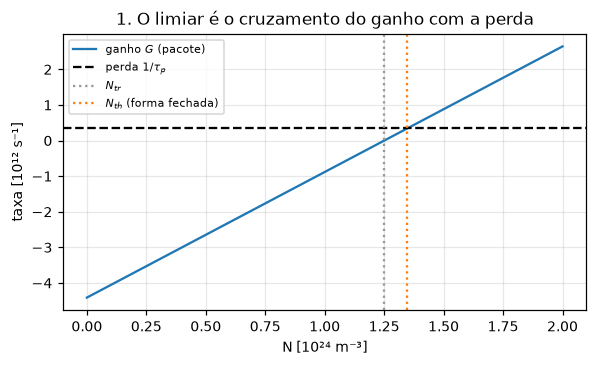

In [2]:
n_eixo = np.linspace(0, 2e24, 201)
fig, ax = plt.subplots(1, 1, figsize=(5.5, 3.4))
ax.plot(n_eixo / 1e24, gain(n_eixo, 0.0, P) / 1e12, color=C3[0], label="ganho $G$ (pacote)")
ax.axhline(1 / R.photon_lifetime / 1e12, color="k", ls="--", label=r"perda $1/\tau_p$")
ax.axvline(CFG.transparency_density / 1e24, color="0.6", ls=":", label="$N_{tr}$")
ax.axvline(R.threshold_density / 1e24, color=C3[1], ls=":", label="$N_{th}$ (forma fechada)")
ax.set(xlabel="N [10²⁴ m⁻³]", ylabel="taxa [10¹² s⁻¹]",
       title="1. O limiar é o cruzamento do ganho com a perda")
ax.legend()
fig.tight_layout()

**Leitura.** A reta do ganho corta a perda exatamente em $N_{th}$ calculado pela forma
fechada. A perda é dominada pelos espelhos e pela perda interna; aumentar qualquer uma
encurta τ_p e desloca o limiar para a direita.

## 2. Estado estacionário: curva $P_{out} \times I$

**Equação.** Em corrente constante as derivadas são nulas. Desprezando $R_{sp}$
(Agrawal, texto antes da Eq. 3.3.6 e Eq. 3.3.7–3.3.10):

- abaixo do limiar: $S = 0$ e $N = \tau_c I/(qV)$;
- acima do limiar: $N = N_{th}$ (o ganho "trava" na perda) e
  $S = \tau_p (I - I_{th})/(qV)$;
- potência por faceta: $P_e = \frac{\hbar\omega}{2q}\,\eta_d\,(I - I_{th})$, com
  $\eta_d = \alpha_{mir}/(\alpha_{mir}+\alpha_{int})$.

A simulação usa `steady_state`, que resolve as equações completas (com $R_{sp}$) sem
assumir a forma acima.

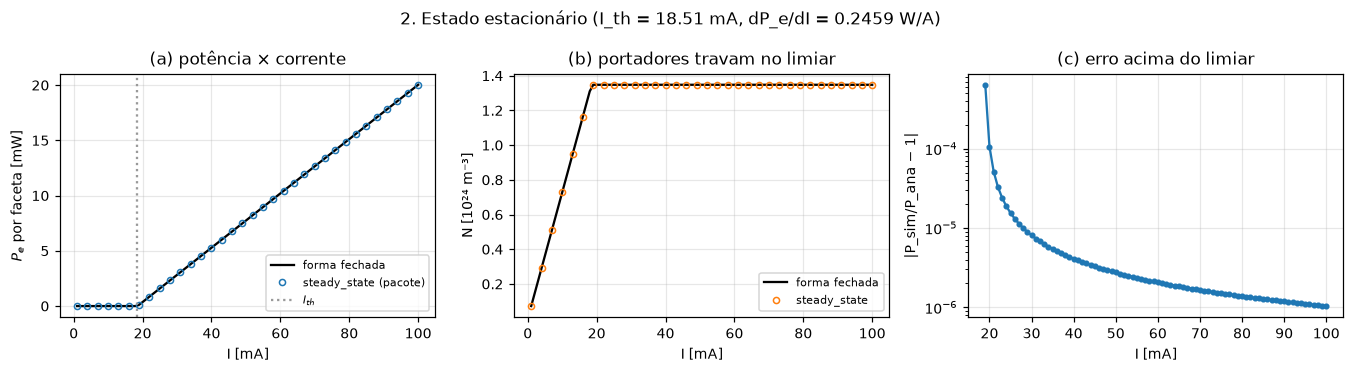

In [3]:
I_eixo = np.linspace(1e-3, 100e-3, 100)
estac = np.array([steady_state(i, P) for i in I_eixo])
N_ss, S_ss = estac[:, 0], estac[:, 1]
Pe_ss = potencia(S_ss)
acima = I_eixo > R.threshold_current
Pe_ana = np.where(acima, R.slope_efficiency * (I_eixo - R.threshold_current), 0.0)
N_ana = np.where(acima, R.threshold_density, CFG.carrier_lifetime * I_eixo / (Q_ELECTRON * R.volume))

fig, ax = plt.subplots(1, 3, figsize=(12.5, 3.4))
ax[0].plot(I_eixo * 1e3, Pe_ana * 1e3, "-", color="k", label="forma fechada")
ax[0].plot(I_eixo[::3] * 1e3, Pe_ss[::3] * 1e3, "o", ms=4, mfc="none", color=C3[0],
           label="steady_state (pacote)")
ax[0].axvline(R.threshold_current * 1e3, color="0.6", ls=":", label="$I_{th}$")
ax[0].set(xlabel="I [mA]", ylabel="$P_e$ por faceta [mW]", title="(a) potência × corrente")
ax[1].plot(I_eixo * 1e3, N_ana / 1e24, "-", color="k", label="forma fechada")
ax[1].plot(I_eixo[::3] * 1e3, N_ss[::3] / 1e24, "o", ms=4, mfc="none", color=C3[1],
           label="steady_state")
ax[1].set(xlabel="I [mA]", ylabel="N [10²⁴ m⁻³]", title="(b) portadores travam no limiar")
erro = np.abs(Pe_ss[acima] / Pe_ana[acima] - 1)
ax[2].semilogy(I_eixo[acima] * 1e3, erro + 1e-18, "o-", ms=3, color=C3[0])
ax[2].set(xlabel="I [mA]", ylabel="|P_sim/P_ana − 1|", title="(c) erro acima do limiar")
for a in ax[:2]: a.legend()
fig.suptitle(f"2. Estado estacionário (I_th = {R.threshold_current*1e3:.2f} mA, "
             f"dP_e/dI = {R.slope_efficiency:.4f} W/A)")
fig.tight_layout()

**Leitura.** Acima do limiar a potência cresce linearmente com a corrente, e N fica parado
em $N_{th}$: toda corrente adicional vira fótons. O erro em (c) é a emissão espontânea, que
a forma fechada despreza: $R_{sp}$ soma fótons e arredonda o joelho da curva, por isso o
erro é maior perto do limiar (6e-4) e cai com a corrente. Abaixo do limiar a potência é
praticamente zero (só emissão espontânea, menos de um fóton na cavidade em 10 mA) e N cresce
linearmente com I.

Testes: issue #14.

## 3. Ligando o laser: $N(t)$ e $S(t)$ para um degrau de corrente

Os gráficos da aula: N × t para uma corrente de polarização, e embaixo o fluxo de fótons
S × t. O laser parte de N = S = 0 e a corrente sobe em degrau em t = 0.

**Forma fechada parcial** [dedução do guia, seção 3.2]: enquanto S ≈ 0, a Eq. de dN/dt
vira $dN/dt = I/(qV) - N/\tau_c$, e N atinge $N_{th}$ no instante
$t_d = \tau_c \ln[I/(I - I_{th})]$ (partindo de N = 0). A partir daí S cresce. Os valores
finais são os do estado estacionário da seção 2.

I = 30 mA: t_d (forma fechada) = 2016 ps; S atinge metade do final em 2125 ps; S final / estacionário = 1.000000


I = 60 mA: t_d (forma fechada) = 775 ps; S atinge metade do final em 839 ps; S final / estacionário = 1.000000


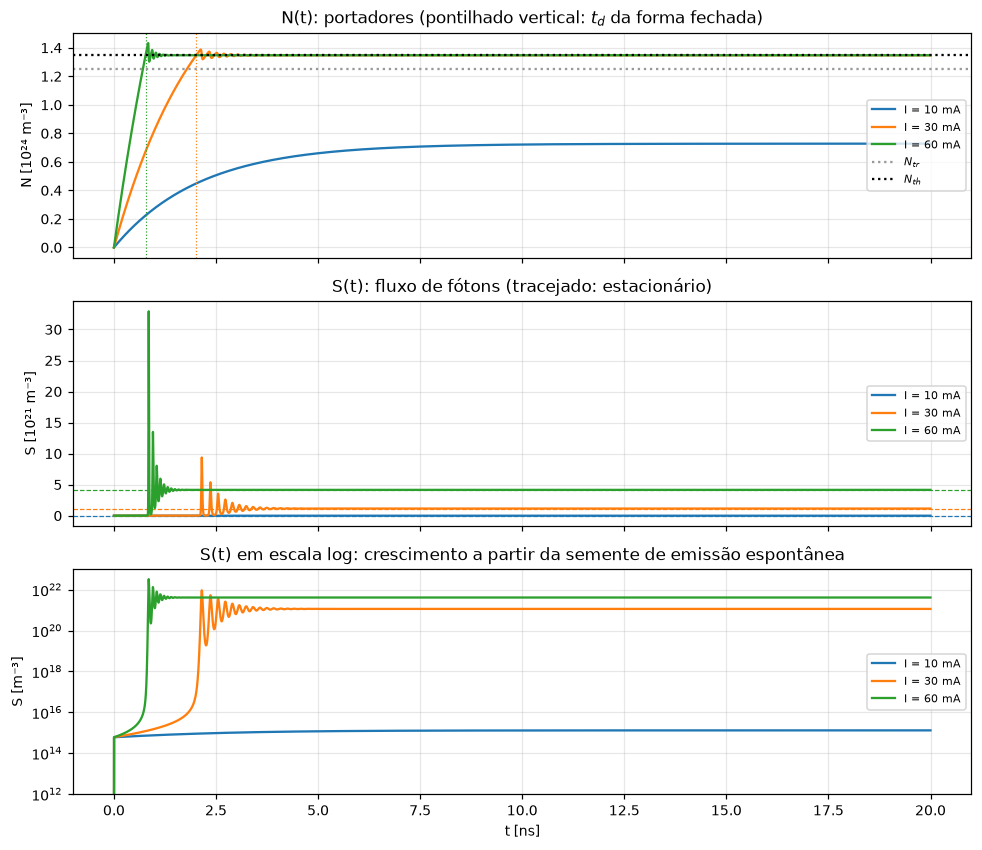

In [4]:
DT = 1e-12                       # grade de 1 ps; o integrador usa subpassos de 0,1 ps
T_SIM = 20e-9
t = np.arange(int(T_SIM / DT)) * DT
correntes = [10e-3, 30e-3, 60e-3]
fig, ax = plt.subplots(3, 1, figsize=(9, 7.8), sharex=True)
for i, I0 in enumerate(correntes):
    N_t, S_t, _ = integrate(np.full(t.size, I0), DT, P, 0.0, 0.0)
    n_f, s_f = steady_state(I0, P)
    ax[0].plot(t * 1e9, N_t / 1e24, color=C3[i], label=f"I = {I0*1e3:.0f} mA")
    ax[1].plot(t * 1e9, S_t / 1e21, color=C3[i], label=f"I = {I0*1e3:.0f} mA")
    ax[1].axhline(s_f / 1e21, color=C3[i], ls="--", lw=0.8)
    ax[2].semilogy(t * 1e9, np.maximum(S_t, 1e-40), color=C3[i], label=f"I = {I0*1e3:.0f} mA")
    if I0 > R.threshold_current:
        td = CFG.carrier_lifetime * np.log(I0 / (I0 - R.threshold_current))
        ax[0].axvline(td * 1e9, color=C3[i], ls=":", lw=0.8)
        k = np.argmax(S_t > 0.5 * s_f)
        print(f"I = {I0*1e3:.0f} mA: t_d (forma fechada) = {td*1e12:.0f} ps; "
              f"S atinge metade do final em {t[k]*1e12:.0f} ps; "
              f"S final / estacionário = {S_t[-1]/s_f:.6f}")
ax[0].axhline(CFG.transparency_density / 1e24, color="0.6", ls=":", label="$N_{tr}$")
ax[0].axhline(R.threshold_density / 1e24, color="k", ls=":", label="$N_{th}$")
ax[0].set(ylabel="N [10²⁴ m⁻³]", title="N(t): portadores (pontilhado vertical: $t_d$ da forma fechada)")
ax[1].set(ylabel="S [10²¹ m⁻³]", title="S(t): fluxo de fótons (tracejado: estacionário)")
ax[2].set(xlabel="t [ns]", ylabel="S [m⁻³]", ylim=(1e12, 1e23),
          title="S(t) em escala log: crescimento a partir da semente de emissão espontânea")
for a in ax: a.legend(loc="right")
fig.tight_layout()

**Leitura.**
- Em 10 mA (abaixo do limiar) N sobe até $\tau_c I/(qV)$, abaixo até de $N_{tr}$, e não há
  emissão.
- Em 30 e 60 mA, N passa de $N_{th}$, os fótons crescem, consomem portadores, e N volta ao
  limiar oscilando: são as **oscilações de relaxação** (seção 4). Depois de alguns
  nanossegundos S chega ao estacionário da seção 2.
- A fórmula de $t_d$ acerta o instante em que N cruza $N_{th}$ (linhas pontilhadas no
  painel de cima). A luz, porém, só aparece 60 a 110 ps depois (ver a saída da célula):
  acima do limiar S cresce exponencialmente, mas a semente é só a emissão espontânea. O
  painel em escala log mostra S saltando logo no início para ~1e15 m⁻³ (menos de um fóton
  na cavidade), crescendo devagar enquanto N se aproxima de $N_{th}$ e, depois de $t_d$,
  subindo seis a sete ordens de grandeza. $R_{sp}$ controla, portanto, quanto tempo
  o laser leva para ligar além de $t_d$: com o $R_{sp}$ antigo do notebook do professor
  (≈ 4e-16 m⁻³s⁻¹, trocado pelo do Agrawal em 2026-10-16) esse atraso extra era de 400 ps
  em 30 mA. Durante esse tempo N continua subindo acima de $N_{th}$, o que explica o
  primeiro pico de fótons muito acima do estacionário.

Testes: issue #14.

## 4. Oscilações de relaxação

**Forma fechada** (Agrawal, Eq. 3.3.20–3.3.21, em densidade): perto do estacionário,
uma pequena perturbação oscila com frequência $\Omega_R$ e decai com taxa $\Gamma_R$:

$$\Omega_R = \left[G\,g_c S - \tfrac{(\Gamma_P - \Gamma_N)^2}{4}\right]^{1/2},\quad
\Gamma_R = \tfrac{\Gamma_P + \Gamma_N}{2},\quad
\Gamma_P = \tfrac{R_{sp}}{S} + \varepsilon G S,\quad \Gamma_N = \tfrac{1}{\tau_c} + g_c S$$

Como S cresce com a corrente, $\Omega_R$ também cresce: é por isso que polarizar o laser
mais alto aumenta a banda de modulação (Eq. 3.3.24). A simulação aplica um degrau de
+1 mA a partir do estacionário e mede a frequência pelos cruzamentos de zero de
$S(t) - S_{final}$.

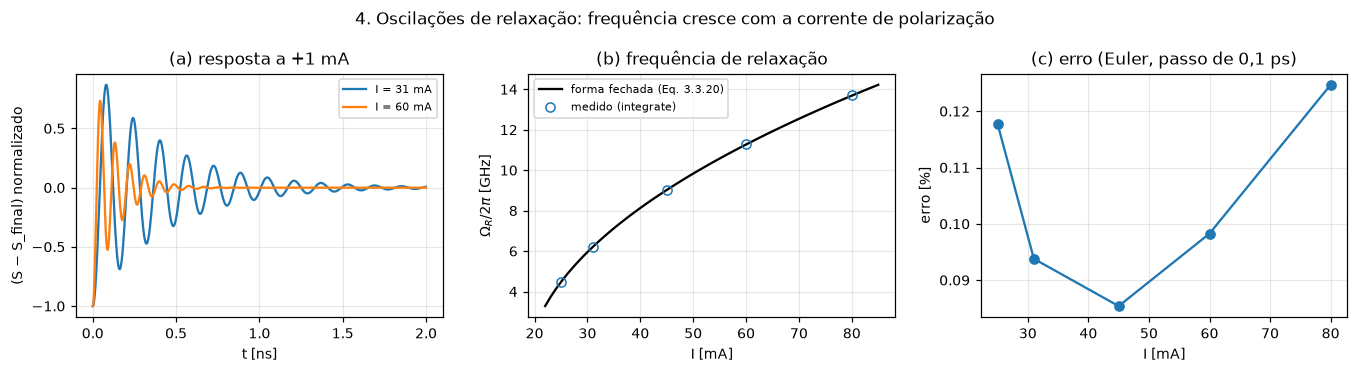

In [5]:
def omega_gamma_ana(I0):
    s = steady_state(I0, P)[1]
    G = 1 / P.photon_lifetime - P.spontaneous_emission_rate / s
    gp = P.spontaneous_emission_rate / s + P.gain_compression * G * s
    gn = 1 / P.carrier_lifetime + P.gain_coefficient * s
    return np.sqrt(G * P.gain_coefficient * s - (gp - gn) ** 2 / 4), (gp + gn) / 2

def omega_medido(I0, n=8000):
    n0, s0 = steady_state(I0 - 1e-3, P)
    _, S_t, _ = integrate(np.full(n, I0), DT, P, n0, s0)
    x = S_t - steady_state(I0, P)[1]
    i = np.where(np.diff(np.sign(x)) != 0)[0][:9]
    cz = i * DT - x[i] * DT / (x[i + 1] - x[i])
    return 2 * np.pi / (2 * np.mean(np.diff(cz))), x

fig, ax = plt.subplots(1, 3, figsize=(12.5, 3.4))
I_bias = np.array([25e-3, 31e-3, 45e-3, 60e-3, 80e-3])
med, ana = [], []
for i, I0 in enumerate(I_bias):
    om, x = omega_medido(I0)
    med.append(om); ana.append(omega_gamma_ana(I0)[0])
    if i in (1, 3):
        tt = np.arange(x.size) * DT
        ax[0].plot(tt[:2000] * 1e9, x[:2000] / abs(x[0]), color=C3[i // 2],
                   label=f"I = {I0*1e3:.0f} mA")
I_fino = np.linspace(22e-3, 85e-3, 60)
ax[1].plot(I_fino * 1e3, [omega_gamma_ana(i)[0] / 2 / np.pi / 1e9 for i in I_fino], "k-",
           label="forma fechada (Eq. 3.3.20)")
ax[1].plot(I_bias * 1e3, np.array(med) / 2 / np.pi / 1e9, "o", mfc="none", color=C3[0],
           label="medido (integrate)")
ax[2].plot(I_bias * 1e3, np.abs(np.array(med) / np.array(ana) - 1) * 100, "o-", color=C3[0])
ax[0].set(xlabel="t [ns]", ylabel="(S − S_final) normalizado", title="(a) resposta a +1 mA")
ax[1].set(xlabel="I [mA]", ylabel="$\\Omega_R/2\\pi$ [GHz]", title="(b) frequência de relaxação")
ax[2].set(xlabel="I [mA]", ylabel="erro [%]", title="(c) erro (Euler, passo de 0,1 ps)")
for a in ax[:2]: a.legend()
fig.suptitle("4. Oscilações de relaxação: frequência cresce com a corrente de polarização")
fig.tight_layout()

**Leitura.** A frequência medida segue a forma fechada; a diferença (~0,1–1 %) vem do
Euler, de 1ª ordem, e cresce com $\Omega_R$ (o erro relativo é ~ $\Omega_R h/2$, com
h = 0,1 ps). Em (a) a oscilação de 60 mA é mais rápida e mais amortecida que a de 31 mA:
$\Gamma_N$ cresce com S.

Testes: issue #14.

## 5. Resposta de pequeno sinal: $H(\omega)$ e banda de modulação

**Conceito.** Polarizado acima do limiar em $I_b$, o laser recebe uma modulação pequena
$I(t) = I_b + \Delta I \sin(\omega t)$. A densidade de fótons responde com a mesma
frequência, com amplitude e atraso que dependem de ω. A razão entre a resposta em ω e a
resposta em ω → 0 é a função de transferência $H(\omega)$; a frequência em que $|H|$ cai a
1/2 é a banda de modulação $f_{3dB}$ (Agrawal, Eq. 3.3.22–3.3.23: 3 dB de potência óptica).

**Equação.** Linearizando as equações de taxa em torno do estacionário $(N_b, S_b)$
(Agrawal, Eq. 3.3.19–3.3.21):

$$\frac{\delta S}{\delta I}(\omega) = \frac{a_{SN}/(qV)}{\Omega_R^2 + \Gamma_R^2 - \omega^2 + 2i\omega\Gamma_R},
\qquad \Gamma_R = \frac{\Gamma_P + \Gamma_N}{2},\qquad
\Omega_R^2 + \Gamma_R^2 = \Gamma_P\Gamma_N + a_{SN}a_{NS}$$

com $a_{SN} = S_b\,\partial G/\partial N$, $a_{NS} = G_b + S_b\,\partial G/\partial S$,
$\Gamma_P = R_{sp}/S_b - S_b\,\partial G/\partial S$ e $\Gamma_N = 1/\tau_c + S_b\,\partial G/\partial N$.

**Compressão de ganho** (decisão de 2026-10-15): $\varepsilon_{NL} = 10^{-7}$ por fóton, valor
típico do Agrawal (texto após a Eq. 3.3.15), que em densidade dá
$\varepsilon = \varepsilon_{NL} V$ = 1,8e-23 m³ para este laser. O livro descarta os termos
de ordem $\varepsilon P$ (válido para $\varepsilon P \ll 1$); o pacote usa a linearização
completa (`kernels/laser/small_signal.py`), que coincide com o livro quando ε = 0. As
linhas tracejadas abaixo são a fórmula literal do livro, para comparação.

A simulação modula a corrente com ΔI = 0,05 mA e mede a componente de S na frequência
de modulação (projeção sobre $e^{-i\omega t}$ num número inteiro de períodos, depois do
transiente).

I = 30 mA: ε·S = 0.021 | Ω_R/2π = 5.83 GHz | Γ_R = 5.877e+09 1/s | f_3dB = 10.10 GHz
I = 60 mA: ε·S = 0.075 | Ω_R/2π = 10.38 GHz | Γ_R = 2.097e+10 1/s | f_3dB = 18.01 GHz
I = 90 mA: ε·S = 0.129 | Ω_R/2π = 12.60 GHz | Γ_R = 3.676e+10 1/s | f_3dB = 21.94 GHz


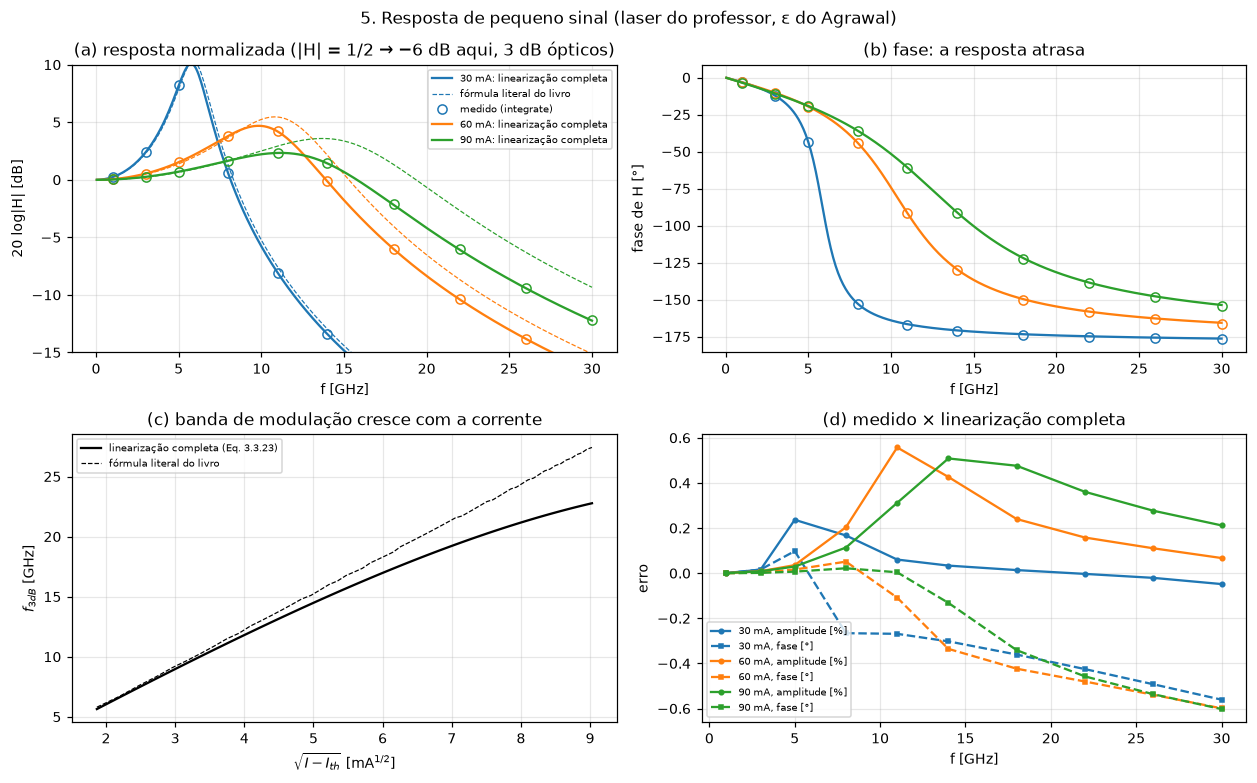

In [6]:
PA = params(CFG, R, gain_compression=1e-7 * R.volume)

def medir_resposta(f, i0, di, p, dt=0.5e-12, max_step=0.05e-12, t_acom=3e-9):
    """dS/dI medido com o integrador (lock-in em f), como amplitude*exp(i*fase)."""
    n_per = max(4, int(np.ceil(2e-9 * f)))
    n_acom, n_med = int(round(t_acom / dt)), int(round(n_per / f / dt))
    tt = np.arange(n_acom + n_med + 1) * dt
    n0, s0 = steady_state(i0, p)
    _, s, _ = integrate(i0 + di * np.sin(2 * np.pi * f * tt), dt, p, n0, s0, max_step=max_step)
    t_m, x = tt[n_acom:n_acom + n_med], s[n_acom:n_acom + n_med]
    return 1j * 2 * np.mean((x - x.mean()) * np.exp(-2j * np.pi * f * t_m)) / di

def agrawal_literal(f, i0, p):
    """H(omega) com Omega_R e Gamma_R literais do livro (Eq. 3.3.20-3.3.22)."""
    n, s = steady_state(i0, p)
    g = gain(n, s, p)
    gp = p.spontaneous_emission_rate / s + p.gain_compression * g * s
    gn = 1 / p.carrier_lifetime + p.gain_coefficient * s
    a = g * p.gain_coefficient * s + gp * gn          # Omega_R^2 + Gamma_R^2
    w = 2 * np.pi * np.asarray(f)
    return a / (a - w ** 2 + 1j * w * (gp + gn))

I_ss = [30e-3, 60e-3, 90e-3]           # as correntes do notebook do professor
f_eixo = np.linspace(0.05e9, 30e9, 400)
f_med = np.array([1, 3, 5, 8, 11, 14, 18, 22, 26, 30]) * 1e9
fig, ax = plt.subplots(2, 2, figsize=(11.5, 7.2))
ax = ax.ravel()
for i, i0 in enumerate(I_ss):
    dc = modulation_response(0.0, i0, PA)
    H = normalized_modulation_response(f_eixo, i0, PA)
    medido = np.array([medir_resposta(f, i0, 0.05e-3, PA) for f in f_med])
    teoria = modulation_response(f_med, i0, PA)
    ax[0].plot(f_eixo / 1e9, 20 * np.log10(np.abs(H)), "-", color=C3[i],
               label=f"{i0*1e3:.0f} mA: linearização completa")
    ax[0].plot(f_eixo / 1e9, 20 * np.log10(np.abs(agrawal_literal(f_eixo, i0, PA))), "--",
               color=C3[i], lw=0.8, label="fórmula literal do livro" if i == 0 else None)
    ax[0].plot(f_med / 1e9, 20 * np.log10(np.abs(medido / dc)), "o", mfc="none", color=C3[i],
               label="medido (integrate)" if i == 0 else None)
    ax[1].plot(f_eixo / 1e9, np.degrees(np.angle(H)), "-", color=C3[i])
    ax[1].plot(f_med / 1e9, np.degrees(np.angle(medido / dc)), "o", mfc="none", color=C3[i])
    ax[3].plot(f_med / 1e9, (np.abs(medido) / np.abs(teoria) - 1) * 100, "o-", ms=3,
               color=C3[i], label=f"{i0*1e3:.0f} mA, amplitude [%]")
    ax[3].plot(f_med / 1e9, np.degrees(np.angle(medido / teoria)), "s--", ms=3, color=C3[i],
               label=f"{i0*1e3:.0f} mA, fase [°]")
I_f3 = np.linspace(22e-3, 100e-3, 60)
f3_completa = [bandwidth_3db(i, PA) for i in I_f3]
f3_livro = []
for i in I_f3:
    Hl = np.abs(agrawal_literal(f_eixo * 2, i, PA))
    f3_livro.append((f_eixo * 2)[np.argmax(Hl < 0.5)])
ax[2].plot(np.sqrt((I_f3 - R.threshold_current) * 1e3), np.array(f3_completa) / 1e9, "k-",
           label="linearização completa (Eq. 3.3.23)")
ax[2].plot(np.sqrt((I_f3 - R.threshold_current) * 1e3), np.array(f3_livro) / 1e9, "k--",
           lw=0.8, label="fórmula literal do livro")
ax[0].set(ylim=(-15, 10), xlabel="f [GHz]", ylabel="20 log|H| [dB]",
          title="(a) resposta normalizada (|H| = 1/2 → −6 dB aqui, 3 dB ópticos)")
ax[1].set(xlabel="f [GHz]", ylabel="fase de H [°]", title="(b) fase: a resposta atrasa")
ax[2].set(xlabel=r"$\sqrt{I - I_{th}}$ [mA$^{1/2}$]", ylabel="$f_{3dB}$ [GHz]",
          title="(c) banda de modulação cresce com a corrente")
ax[3].set(xlabel="f [GHz]", ylabel="erro", title="(d) medido × linearização completa")
for a in (ax[0], ax[2], ax[3]): a.legend(fontsize=6.5)
fig.suptitle("5. Resposta de pequeno sinal (laser do professor, ε do Agrawal)")
fig.tight_layout()
for i0 in I_ss:
    ss = linearize(i0, PA)
    print(f"I = {i0*1e3:.0f} mA: ε·S = {PA.gain_compression*ss.photon_density:.3f} | "
          f"Ω_R/2π = {ss.omega_r/2/np.pi/1e9:.2f} GHz | Γ_R = {ss.gamma_r:.3e} 1/s | "
          f"f_3dB = {bandwidth_3db(i0, PA)/1e9:.2f} GHz")

**Leitura.**
- (a) A resposta é plana em baixa frequência, tem um pico perto de $\Omega_R/2\pi$ e cai
  rapidamente acima dele, como na Fig. 3.13 do Agrawal. Polarizar mais alto desloca o pico
  para a direita e o achata: $\Omega_R$ cresce com S, e o amortecimento $\Gamma_R$ também.
- (b) A fase passa por −90° perto da ressonância e tende a −180°: a luz atrasa em relação à
  corrente.
- (c) A banda cresce com $\sqrt{I - I_{th}}$ (Eq. 3.3.24) enquanto a compressão é pequena e
  satura quando $\varepsilon S$ cresce. A fórmula literal do livro superestima a banda nas
  correntes altas porque descarta os termos de ordem $\varepsilon S$ (que chega a 0,13 em
  90 mA, ver a saída da célula).
- (d) O integrador concorda com a linearização completa em < 0,6 % na amplitude e
  < 0,6° na fase: o erro restante é o do Euler com passo de 0,05 ps. A fórmula literal do
  livro, em (a), se afasta dos pontos medidos em 60 e 90 mA.

Com o ε do notebook do professor (1e-22 m³, cinco vezes maior), $\varepsilon S$ passa de
0,2 a partir de ~40 mA e a resposta fica superamortecida: não há pico de ressonância.

Testes: issue #14.

## 6. Pulso quadrado de corrente → pulso de luz

O gráfico "entrada × saída" da aula, com o laser do professor (potência em watts): a
corrente fica em $I_b = I_{th}$ e sobe a $I_{on} = 3\,I_{th}$ durante 200 ps
(decisão de 2026-10-15). Compressão de ganho do Agrawal, como na seção 5.

Não há forma fechada para modulação de grande sinal. Como o laser já está no limiar,
$t_d = \tau_c \ln[(I_{on} - I_b)/(I_{on} - I_{th})] = 0$: N não precisa subir até o limiar,
e o atraso que sobra é só o tempo de os fótons crescerem a partir do valor estacionário em
$I_{th}$.

Convenção do chirp (decisão de 2026-10-15): δν > 0 é deslocamento para o **azul**, como na
Fig. 3.16 do Agrawal.

pico de 33.1 mW em 76 ps após o início do pulso; acima de 50 % do pico de 66 a 93 ps


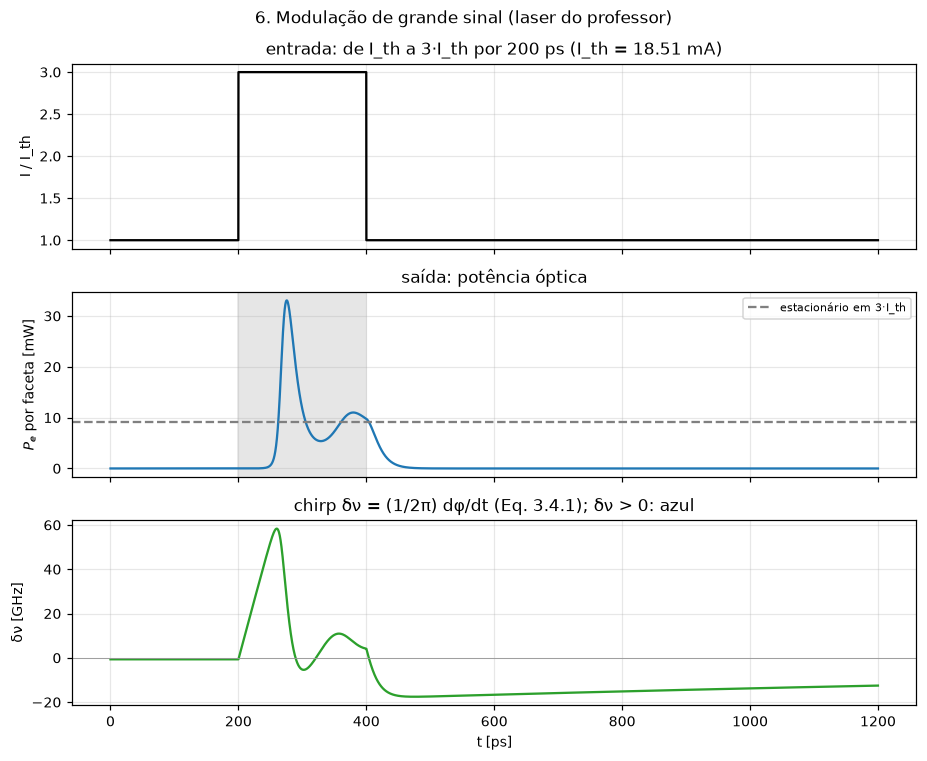

In [7]:
I_on = 3 * R.threshold_current
dt6p = 0.1e-12
t6p = np.arange(int(1.2e-9 / dt6p)) * dt6p
t_ini, dur = 0.2e-9, 200e-12
I_t = np.where((t6p >= t_ini) & (t6p < t_ini + dur), I_on, R.threshold_current)
n0, s0 = steady_state(R.threshold_current, PA)
N6p, S6p, phi6p = integrate(I_t, dt6p, PA, n0, s0)
Pe6p = potencia(S6p)
chirp = np.gradient(phi6p, dt6p) / (2 * np.pi)

fig, ax = plt.subplots(3, 1, figsize=(8.5, 7), sharex=True)
ax[0].plot(t6p * 1e12, I_t / R.threshold_current, color="k")
ax[0].set(ylabel="I / I_th", title=f"entrada: de I_th a 3·I_th por 200 ps (I_th = {R.threshold_current*1e3:.2f} mA)")
ax[1].plot(t6p * 1e12, Pe6p * 1e3, color=C3[0])
ax[1].axhline(potencia(steady_state(I_on, PA)[1]) * 1e3, color="0.5", ls="--",
              label="estacionário em 3·I_th")
ax[1].axvspan(t_ini * 1e12, (t_ini + dur) * 1e12, color="0.9", zorder=0)
ax[1].set(ylabel="$P_e$ por faceta [mW]", title="saída: potência óptica")
ax[1].legend()
ax[2].plot(t6p * 1e12, chirp / 1e9, color=C3[2])
ax[2].axhline(0, color="0.6", lw=0.6)
ax[2].set(xlabel="t [ps]", ylabel="δν [GHz]", title="chirp δν = (1/2π) dφ/dt (Eq. 3.4.1); δν > 0: azul")
fig.suptitle("6. Modulação de grande sinal (laser do professor)")
fig.tight_layout()
k_pico = np.argmax(Pe6p)
acima = t6p[Pe6p > 0.5 * Pe6p.max()]
print(f"pico de {Pe6p.max()*1e3:.1f} mW em {(t6p[k_pico]-t_ini)*1e12:.0f} ps após o início do pulso; "
      f"acima de 50 % do pico de {(acima[0]-t_ini)*1e12:.0f} a {(acima[-1]-t_ini)*1e12:.0f} ps")

**Leitura.** (Os números citados estão na saída da célula.)
- A potência não acompanha o degrau de corrente. Durante ~65 ps quase não há luz: os
  fótons partem do valor estacionário no limiar, que é pequeno (~190 fótons na cavidade), e
  crescem enquanto N sobe acima de $N_{th}$. Quando ficam grandes, consomem de uma vez o
  excesso de portadores e formam um pico 3,6 vezes maior que o estacionário de 3·I_th
  (linha tracejada). Depois do pico a potência cai abaixo do estacionário (os portadores
  ficaram abaixo do limiar) e volta numa segunda oscilação de relaxação, menor, antes do
  fim do pulso.
- Quando a corrente volta a $I_{th}$, a potência cai a 10 % em ~40 ps. Os portadores voltam ao
  limiar devagar, na escala de $\tau_c$: por isso o chirp fica negativo por mais de 1 ns
  depois do pulso.
- O chirp acompanha N: positivo (azul) enquanto N está acima do limiar, na subida do
  pulso, e negativo (vermelho) quando os fótons consomem os portadores. É o comportamento
  descrito para a Fig. 3.16 do Agrawal.
- Antes do pulso o chirp não é zero, e sim −0,64 GHz: no estacionário em $I_{th}$ o ganho
  fica um pouco abaixo da perda ($G = 1/\tau_p - R_{sp}/S$), e a fase gira devagar. É um
  desvio constante da frequência óptica que depende da corrente de polarização. O bloco do
  transmissor (seção 9) desconta esse desvio na polarização, para a portadora ficar na
  frequência do canal (decisão de 2026-10-22).

Sem forma fechada para a forma do pulso.

## 7. Ruído: forças de Langevin

**Conceito** (Agrawal, seção 3.3.8). Cada fóton emitido espontaneamente soma ao campo um
pequeno componente de fase aleatória. A intensidade e a fase do laser flutuam: a intensidade
dá o ruído RIN, a fase dá a largura de linha. Isso acontece mesmo em corrente constante.

**Equação** (Agrawal, Eq. 3.3.25–3.3.28, em densidade). Cada equação ganha uma força
aleatória gaussiana de média zero, com $\langle F_i(t) F_j(t')\rangle = 2D_{ij}\,\delta(t - t')$:

$$\frac{dS}{dt} = (G - \tau_p^{-1})S + R_{sp} + F_S,\qquad
\frac{d\phi}{dt} = \frac{\alpha_H}{2}\left[g_c(N - N_{tr}) - \tau_p^{-1}\right] + F_\phi,\qquad
D_{SS} = R_{sp}S,\quad D_{\phi\phi} = \frac{R_{sp}}{4S}$$

Os outros coeficientes são desprezados, como no Agrawal. No integrador (Euler–Maruyama),
cada subpasso h soma $\sqrt{2Dh}\,\xi$, com ξ normal padrão: o ruído cresce com
$\sqrt{h}$, não com h. A emissão espontânea é a do Agrawal, $R_{sp} = n_{sp}G$ avaliado no
limiar, $R_{sp} = n_{sp}/(\tau_p V)$ em densidade (decisão de 2026-10-16).

**Forma fechada.** Desprezando as flutuações de intensidade, a variância da fase cresce
linearmente com o atraso, mais um termo das oscilações de relaxação (Eq. 3.3.35–3.3.36):

$$\sigma^2(\tau) = \frac{R_{sp}}{2S}\left\{(1 + \alpha_H^2 b)\,\tau + \frac{\alpha_H^2 b}{2\Gamma_R\cos\delta}
\left[\cos 3\delta - e^{-\Gamma_R\tau}\cos(\Omega_R\tau - 3\delta)\right]\right\},\quad
b = \frac{\Omega_R}{\sqrt{\Omega_R^2 + \Gamma_R^2}},\quad \delta = \tan^{-1}\frac{\Gamma_R}{\Omega_R}$$

e o espectro é uma lorentziana de largura (Eq. 3.3.37, com b = 1; o V cancela):

$$\Delta\nu = \frac{R_{sp}(1 + \alpha_H^2)}{4\pi S}$$

A largura cai com a potência e é multiplicada por $1 + \alpha_H^2$ (= 10 aqui) pelo
acoplamento entre fase e portadores. A simulação mede $\sigma^2(\tau)$ num conjunto de
lasers independentes (n0 e s0 como arrays), depois de esperar ~5/Γ_R para o conjunto
esquecer o estado inicial sem ruído. Δν vem da inclinação de $\sigma^2(\tau)$ entre dois
atrasos, o que cancela o termo constante.

1.5·I_th: Δν medido = 2.690 ± 0.229 MHz | Eq. 3.3.37 = 2.468 MHz
2.0·I_th: Δν medido = 1.168 ± 0.045 MHz | Eq. 3.3.37 = 1.234 MHz
3.0·I_th: Δν medido = 0.612 ± 0.024 MHz | Eq. 3.3.37 = 0.617 MHz
4.0·I_th: Δν medido = 0.402 ± 0.014 MHz | Eq. 3.3.37 = 0.411 MHz
6.0·I_th: Δν medido = 0.244 ± 0.009 MHz | Eq. 3.3.37 = 0.247 MHz
flutuação RMS de S em 2·I_th: 1.294 %


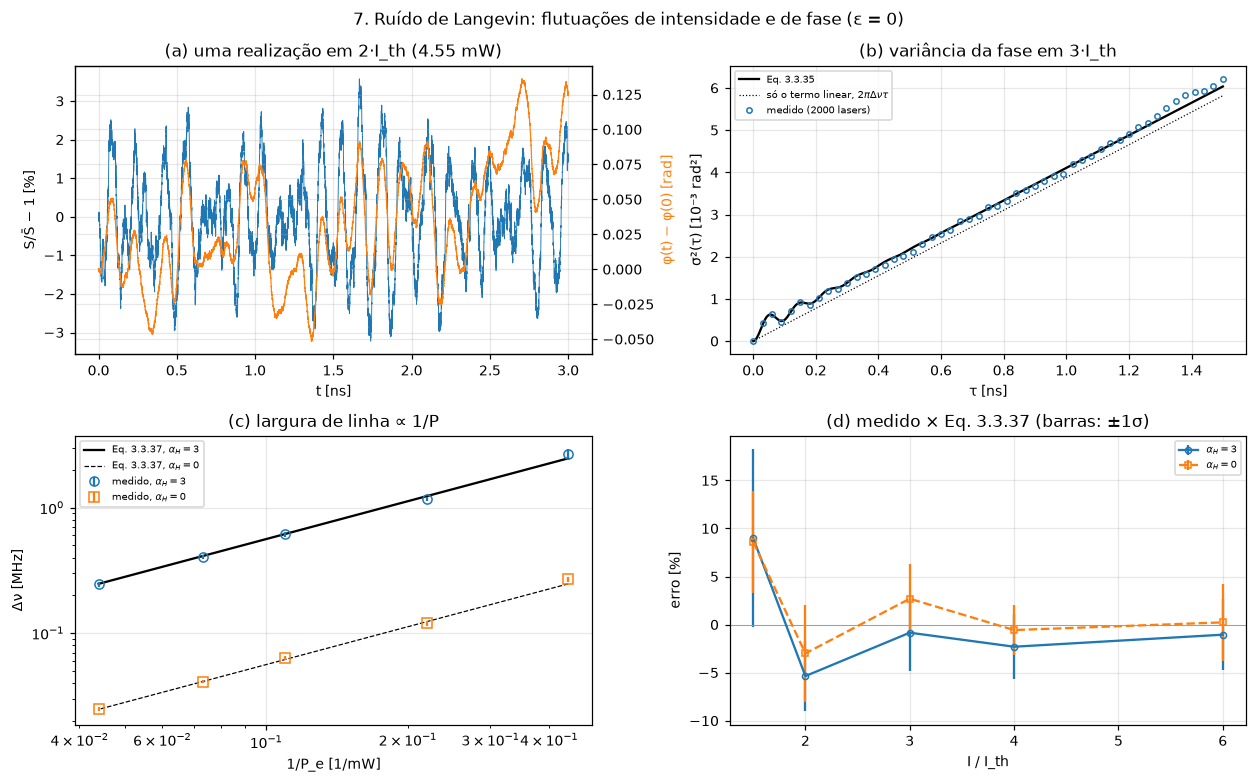

In [8]:
def conjunto(I0, p, M, n_amostras, dt, seed=0):
    """M lasers independentes em corrente constante, partindo do estacionário."""
    n0, s0 = steady_state(I0, p)
    return integrate(np.full(n_amostras, I0), dt, p, np.full(M, n0), np.full(M, s0),
                     max_step=dt, rng=np.random.default_rng(seed))

def sigma2_agrawal(tau, I0, p):
    """Eq. 3.3.35-3.3.36 (eps = 0), com Omega_R e Gamma_R da linearização."""
    ss = linearize(I0, p)
    om, gr = ss.omega_r, ss.gamma_r
    b, d = om / np.hypot(om, gr), np.arctan(gr / om)
    a2b = p.linewidth_enhancement ** 2 * b
    return p.spontaneous_emission_rate / (2 * ss.photon_density) * (
        (1 + a2b) * tau + a2b / (2 * gr * np.cos(d))
        * (np.cos(3 * d) - np.exp(-gr * tau) * np.cos(om * tau - 3 * d)))

def largura_medida(I0, p, M=2000, dt=0.5e-12, lotes=10):
    """Delta_nu pela inclinação de sigma^2 entre 3/Gamma_R e 3/Gamma_R + 1 ns; erro pela
    dispersão entre lotes do conjunto."""
    gr = linearize(I0, p).gamma_r
    j0 = int(np.ceil(5 / gr / dt))
    j1 = j0 + int(np.ceil(3 / gr / dt))
    j2 = j1 + int(round(1e-9 / dt))
    _, _, ph = conjunto(I0, p, M, j2 + 1, dt)
    d1, d2 = ph[:, j1] - ph[:, j0], ph[:, j2] - ph[:, j0]
    est = lambda a, c: (np.var(c) - np.var(a)) / ((j2 - j1) * dt) / (2 * np.pi)
    por_lote = [est(a, c) for a, c in zip(np.split(d1, lotes), np.split(d2, lotes))]
    return est(d1, d2), np.std(por_lote) / np.sqrt(lotes)

# (a) uma realização em 2*I_th
I7 = 2 * R.threshold_current
dt7 = 0.1e-12
n7, s7 = steady_state(I7, P)
_, S7, phi7 = integrate(np.full(30001, I7), dt7, P, n7, s7, max_step=dt7,
                        rng=np.random.default_rng(1))
t7 = np.arange(S7.size) * dt7

# (b) variância da fase em 3*I_th, conjunto de 2000 lasers
I7b, dt7b = 3 * R.threshold_current, 0.2e-12
gr7b = linearize(I7b, P).gamma_r
j0b = int(np.ceil(5 / gr7b / dt7b))
_, _, ph7b = conjunto(I7b, P, 2000, j0b + 7501, dt7b)
tau7b = np.arange(7501) * dt7b
var7b = np.var(ph7b[:, j0b:] - ph7b[:, [j0b]], axis=0)

# (c) largura de linha x potência, com e sem o acoplamento alpha_H
P0 = params(CFG, R, linewidth_enhancement=0.0)
fatores = np.array([1.5, 2, 3, 4, 6])
med3 = np.array([largura_medida(f * R.threshold_current, P) for f in fatores])
med0 = np.array([largura_medida(f * R.threshold_current, P0) for f in fatores])
S_c = np.array([steady_state(f * R.threshold_current, P)[1] for f in fatores])
Pe_c = potencia(S_c)
dnu3 = R.spontaneous_emission_rate * (1 + 3.0 ** 2) / (4 * np.pi * S_c)
dnu0 = R.spontaneous_emission_rate / (4 * np.pi * S_c)

fig, ax = plt.subplots(2, 2, figsize=(11.5, 7.2))
ax = ax.ravel()
ax[0].plot(t7 * 1e9, (S7 / s7 - 1) * 100, color=C3[0], lw=0.6, label="S/S̄ − 1 [%]")
ax0b = ax[0].twinx()
ax0b.plot(t7 * 1e9, phi7 - phi7[0], color=C3[1], lw=0.8)
ax0b.set_ylabel("φ(t) − φ(0) [rad]", color=C3[1])
ax[0].set(xlabel="t [ns]", ylabel="S/S̄ − 1 [%]",
          title=f"(a) uma realização em 2·I_th ({potencia(s7)*1e3:.2f} mW)")
ax[1].plot(tau7b * 1e9, sigma2_agrawal(tau7b, I7b, P) * 1e3, "k-", label="Eq. 3.3.35")
ax[1].plot(tau7b * 1e9, R.spontaneous_emission_rate * (1 + 9) / (2 * steady_state(I7b, P)[1])
           * tau7b * 1e3, "k:", lw=0.8, label=r"só o termo linear, $2\pi\Delta\nu\tau$")
ax[1].plot(tau7b[::150] * 1e9, var7b[::150] * 1e3, "o", ms=3.5, mfc="none", color=C3[0],
           label="medido (2000 lasers)")
ax[1].set(xlabel="τ [ns]", ylabel="σ²(τ) [10⁻³ rad²]", title="(b) variância da fase em 3·I_th")
ax[2].loglog(1 / (Pe_c * 1e3), dnu3 / 1e6, "k-", label=r"Eq. 3.3.37, $\alpha_H = 3$")
ax[2].loglog(1 / (Pe_c * 1e3), dnu0 / 1e6, "k--", lw=0.8, label=r"Eq. 3.3.37, $\alpha_H = 0$")
ax[2].errorbar(1 / (Pe_c * 1e3), med3[:, 0] / 1e6, med3[:, 1] / 1e6, fmt="o", mfc="none",
               color=C3[0], label=r"medido, $\alpha_H = 3$")
ax[2].errorbar(1 / (Pe_c * 1e3), med0[:, 0] / 1e6, med0[:, 1] / 1e6, fmt="s", mfc="none",
               color=C3[1], label=r"medido, $\alpha_H = 0$")
ax[2].set(xlabel="1/P_e [1/mW]", ylabel="Δν [MHz]", title="(c) largura de linha ∝ 1/P")
ax[3].errorbar(fatores, (med3[:, 0] / dnu3 - 1) * 100, med3[:, 1] / dnu3 * 100, fmt="o-",
               ms=4, mfc="none", color=C3[0], label=r"$\alpha_H = 3$")
ax[3].errorbar(fatores, (med0[:, 0] / dnu0 - 1) * 100, med0[:, 1] / dnu0 * 100, fmt="s--",
               ms=4, mfc="none", color=C3[1], label=r"$\alpha_H = 0$")
ax[3].axhline(0, color="0.6", lw=0.6)
ax[3].set(xlabel="I / I_th", ylabel="erro [%]", title="(d) medido × Eq. 3.3.37 (barras: ±1σ)")
for a in ax[1:]: a.legend(fontsize=6.5)
fig.suptitle("7. Ruído de Langevin: flutuações de intensidade e de fase (ε = 0)")
fig.tight_layout()
for f, (m3, e3), d3 in zip(fatores, med3, dnu3):
    print(f"{f:.1f}·I_th: Δν medido = {m3/1e6:.3f} ± {e3/1e6:.3f} MHz | Eq. 3.3.37 = {d3/1e6:.3f} MHz")
print(f"flutuação RMS de S em 2·I_th: {np.std(S7 / s7 - 1) * 100:.3f} %")

**Leitura.** (Os números citados estão na saída da célula.)
- (a) Em 2·I_th a intensidade flutua 1,3 % RMS em torno do estacionário, com a cor das
  oscilações de relaxação (Ω_R/2π = 7,6 GHz aqui). A fase faz um passeio aleatório com
  oscilações na mesma frequência: pelo α_H, cada flutuação de N vira flutuação de fase.
- (b) A variância medida segue a Eq. 3.3.35, inclusive as ondulações do início e o
  degrau constante acima do termo linear (pontilhado), que é o termo das oscilações de
  relaxação. O desvio no fim da curva é estatístico (~3 % com 2000 lasers).
- (c) A largura cai com 1/P, e as duas retas ficam separadas pelo fator
  $1 + \alpha_H^2 = 10$: a maior parte da largura de linha vem do acoplamento entre fase e
  portadores, não da força $F_\phi$ direta.
- (d) O medido fica a ±1–2σ da Eq. 3.3.37 em todas as correntes. As duas curvas usam a
  mesma semente, por isso os erros andam juntos.

**Ligação com o modelo B.** Em 2·I_th (4,55 mW por faceta) este laser tem Δν = 1,23 MHz:
é o número que o parâmetro `linewidth` do laser CW (seção 8) representa sem simular N e S.
O VPI usa 500 kHz. O modelo não reproduz a saturação da largura de linha em 1–10 MHz
observada acima de ~10 mW (Agrawal, Fig. 3.15): pela Eq. 3.3.37 ela continua caindo.

**Poucos fótons** [proposta, guia seção 3.5]. A força gaussiana supõe muitos fótons. Abaixo
do limiar há menos de um fóton na cavidade e um passo de ruído poderia deixar S negativo:
o integrador limita S ≥ 0 e calcula $D_{\phi\phi}$ com S ≥ $R_{sp}\tau_p$ ($n_{sp}$ fótons).

Testes: issue #14.

## 8. Modelo B: laser quase-monocromático (CW)

**Conceito.** Em modulação externa o laser opera em corrente constante e só a fase
flutua. O campo é $E(t) = \sqrt{P}\,e^{i[-2\pi\Delta f\,t + \phi(t)]}$, com $\phi$ um passeio
aleatório (Agrawal, Eq. 3.3.33–3.3.37; código do professor `single_frequency_laser`). Δf é o
desvio de frequência óptica (positivo = azul); o sinal de menos é a convenção do Agrawal,
decidida para o projeto em 2026-10-22 (o professor usa $+2\pi\Delta f\,t$).

**Forma fechada** [dedução, guia seção 2.2]:

$$\langle\Delta\phi^2(\tau)\rangle = 2\pi\,\Delta\nu\,\tau,\qquad
S(f) \propto \frac{1}{1 + [2(f - \Delta f)/\Delta\nu]^2}\quad\text{(lorentziana de largura } \Delta\nu)$$

A largura de linha de 10 MHz abaixo é exagerada em relação ao VPI (500 kHz) só para caber
numa janela curta; a forma não depende do valor.

erro relativo da variância: [-0.001 -0.001 -0.002 -0.003 -0.002 -0.002 -0.006 -0.011]


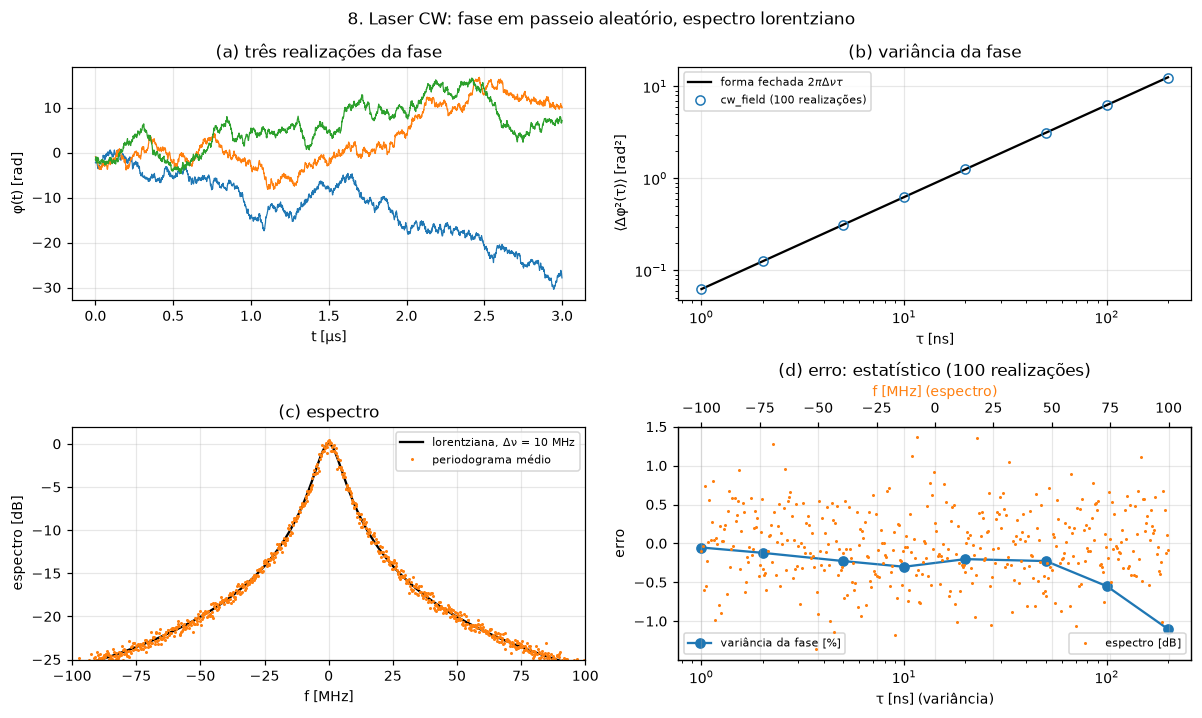

In [9]:
DNU, FS6, N6, REAL = 10e6, 1e9, 2 ** 14, 100
dt6 = 1 / FS6
rng = np.random.default_rng(0)
campos = np.array([cw_field(N6, dt6, 1e-3, DNU, 0.0, rng) for _ in range(REAL)])
atrasos = np.array([1, 2, 5, 10, 20, 50, 100, 200])
fase = np.unwrap(np.angle(campos), axis=1)
var_med = [np.mean((fase[:, a:] - fase[:, :-a]) ** 2) for a in atrasos]
var_ana = 2 * np.pi * DNU * atrasos * dt6
f6 = np.fft.fftshift(np.fft.fftfreq(N6, dt6))
espec = np.fft.fftshift(np.mean(np.abs(np.fft.fft(campos, axis=1)) ** 2, axis=0))
lorentz = 1 / (1 + (2 * f6 / DNU) ** 2)
# Normaliza pela área (potência total), não pelo pico: o pico do periodograma médio é um
# único bin, com ruído estatístico, e normalizar por ele deslocaria a curva inteira.
espec *= lorentz.sum() / espec.sum()

fig, ax = plt.subplots(2, 2, figsize=(11, 6.6))
ax = ax.ravel()
for k in range(3):
    ax[0].plot(np.arange(N6)[:3000] * dt6 * 1e6, fase[k, :3000], lw=0.8)
ax[0].set(xlabel="t [µs]", ylabel="φ(t) [rad]", title="(a) três realizações da fase")
ax[1].loglog(atrasos * dt6 * 1e9, var_ana, "k-", label=r"forma fechada $2\pi\Delta\nu\tau$")
ax[1].loglog(atrasos * dt6 * 1e9, var_med, "o", mfc="none", color=C3[0],
             label=f"cw_field ({REAL} realizações)")
ax[1].set(xlabel="τ [ns]", ylabel="⟨Δφ²(τ)⟩ [rad²]", title="(b) variância da fase")
ax[2].plot(f6 / 1e6, 10 * np.log10(lorentz), "k-", label=f"lorentziana, Δν = {DNU/1e6:.0f} MHz")
ax[2].plot(f6[::4] / 1e6, 10 * np.log10(espec[::4]), ".", ms=2, color=C3[1],
           label="periodograma médio")
ax[2].set(xlim=(-100, 100), ylim=(-25, 2), xlabel="f [MHz]", ylabel="espectro [dB]",
          title="(c) espectro")
banda = np.abs(f6) < 100e6
ax[3].plot(atrasos * dt6 * 1e9, (np.array(var_med) / var_ana - 1) * 100, "o-", color=C3[0],
           label="variância da fase [%]")
ax3b = ax[3].twiny()
ax3b.plot(f6[banda][::8] / 1e6, 10 * np.log10(espec[banda][::8] / lorentz[banda][::8]), ".",
          ms=2, color=C3[1], label="espectro [dB]")
ax3b.set_xlabel("f [MHz] (espectro)", color=C3[1])
ax[3].set(xscale="log", xlabel="τ [ns] (variância)", ylabel="erro",
          title="(d) erro: estatístico (100 realizações)")
ax[3].legend(loc="lower left"); ax3b.legend(loc="lower right")
for a in ax[1:3]: a.legend()
fig.suptitle("8. Laser CW: fase em passeio aleatório, espectro lorentziano")
fig.tight_layout()
print("erro relativo da variância:", np.round(np.array(var_med) / var_ana - 1, 3))

**Leitura.** A variância da fase cresce linearmente com τ (reta de inclinação 1 em escala
log-log), e o espectro médio segue a lorentziana de largura Δν: as duas formas fechadas
da seção 2 do guia. O erro de (b) é estatístico (100 realizações) e cai com mais
realizações. A potência $|E|^2$ não muda com o ruído de fase.

Testes: issue #14.

## 9. Os blocos do transmissor: `DirectModulatedLaser` e `CWLaser`

Os blocos ligam o laser ao resto do simulador com a interface de todo bloco,
`y = bloco(x, ctx)`: recebem um `Waveform` e o contexto, que dá a grade e o gerador
aleatório do canal (`ctx.rng_for(canal, papel)`), e devolvem o campo óptico (2, N), com o
campo na polarização X e Y = 0 (decisão de 2026-10-08).

- `DirectModulatedLaser(laser, frequency, bias_ratio, modulation_ratio)`: o sinal elétrico
  x(t) vira a corrente $I(t) = I_{th}\,[I_b/I_{th} + (I_m/I_{th})\,x(t)]$ (Agrawal,
  Eq. 3.3.14; correntes em múltiplos de $I_{th}$, decisão de 2026-10-16). Parte do
  estacionário em I(0); ruído de Langevin ligado por padrão; potência por faceta.
- `CWLaser(laser, frequency)`: a entrada só fornece a grade e o canal; a saída é a
  portadora da seção 8. Em modulação externa o modulador combina as duas.

Ainda não há gerador de bits nem formatador de pulso no pacote. O sinal elétrico abaixo é
OOK sintético a 10 Gb/s, com bordas de 30 ps feitas por média móvel, de 1,2 a 3·I_th, com o
ε do Agrawal.

saída: (2, 2400), optical, f0 = 0.0 GHz (desvio do canal), canal 0, potência média 3.95 mW
δν médio nos bits 1: 7.68 GHz | nos bits 0: -0.92 GHz
CWLaser com a mesma potência: (2, 2400), potência 3.95 mW, |X|² constante: True


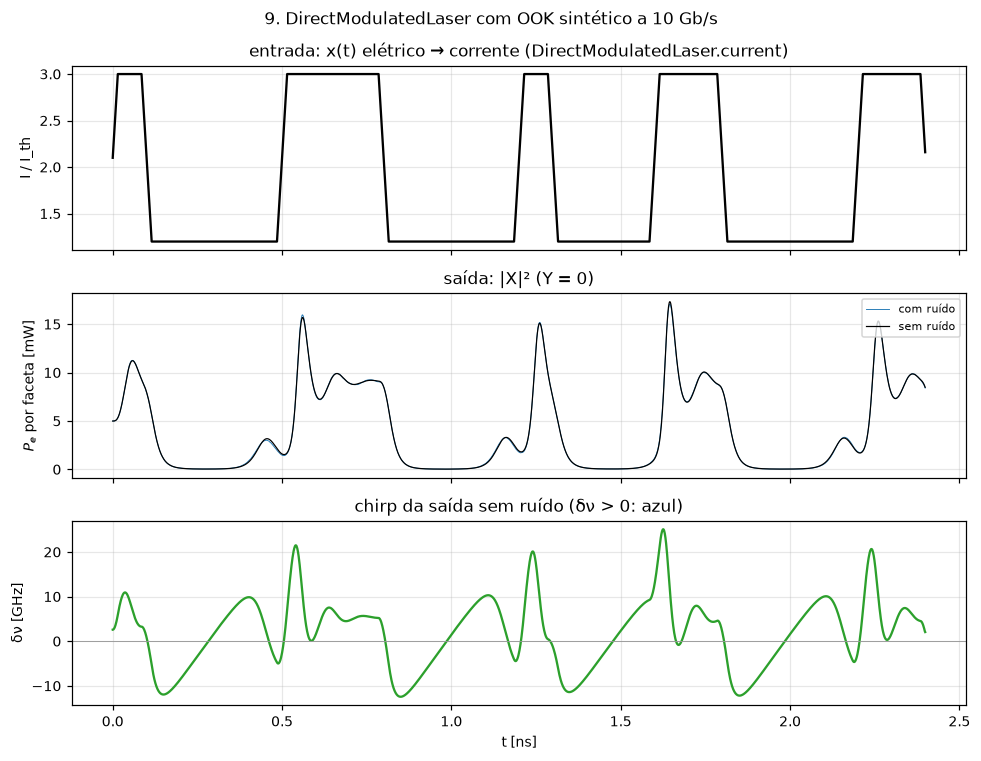

In [10]:
from simcopy.components.tx.laser import CWLaser, DirectModulatedLaser
from simcopy.config.system import CWLaserConfig
from simcopy.core.context import SimContext
from simcopy.core.grid import TimeGrid
from simcopy.core.signals import Domain, SignalGeometry, Waveform

SPS9 = 100                                   # grade de 1 ps, 10 Gb/s
bits9 = np.random.default_rng(3).integers(0, 2, 24)
nrz9 = np.convolve(np.repeat(bits9.astype(float), SPS9), np.ones(30) / 30, mode="same")
grade9 = TimeGrid(1e12, nrz9.size)
x9 = Waveform(samples=nrz9.astype(complex)[None, :], grid=grade9, domain=Domain.ELECTRICAL,
              geometry=SignalGeometry(n_symbols=bits9.size, bits_per_symbol=1,
                                      samples_per_symbol=SPS9, n_pol=1),
              channel_id=0)
ctx9 = SimContext(grid=grade9, root_seed=1)
dml9 = DirectModulatedLaser(dataclasses.replace(CFG, gain_compression=1e-7 * R.volume),
                            F_LASER, bias_ratio=1.2, modulation_ratio=1.8)
y9 = dml9(x9, ctx9)
y9_det = dataclasses.replace(dml9, noise=False)(x9, ctx9)
cw9 = CWLaser(CWLaserConfig(power=y9.power, linewidth=1e6), F_LASER)(x9, ctx9)
t9 = grade9.time
# Convenção do Agrawal: δν = −(1/2π)·d(arg E)/dt (Eq. 2.4.12); o bloco devolve E ∝ exp(−iφ).
chirp9 = -np.gradient(np.unwrap(np.angle(y9_det.samples[0])), grade9.dt) / (2 * np.pi)

fig, ax = plt.subplots(3, 1, figsize=(9, 7), sharex=True)
ax[0].plot(t9 * 1e9, dml9.current(x9) / R.threshold_current, color="k")
ax[0].set(ylabel="I / I_th", title="entrada: x(t) elétrico → corrente (DirectModulatedLaser.current)")
ax[1].plot(t9 * 1e9, np.abs(y9.samples[0]) ** 2 * 1e3, color=C3[0], lw=0.6, label="com ruído")
ax[1].plot(t9 * 1e9, np.abs(y9_det.samples[0]) ** 2 * 1e3, color="k", lw=0.8, label="sem ruído")
ax[1].set(ylabel="$P_e$ por faceta [mW]", title="saída: |X|² (Y = 0)")
ax[1].legend(loc="upper right")
ax[2].plot(t9 * 1e9, chirp9 / 1e9, color=C3[2])
ax[2].axhline(0, color="0.6", lw=0.6)
ax[2].set(xlabel="t [ns]", ylabel="δν [GHz]", title="chirp da saída sem ruído (δν > 0: azul)")
fig.suptitle("9. DirectModulatedLaser com OOK sintético a 10 Gb/s")
fig.tight_layout()
um, zero = nrz9 > 0.99, nrz9 < 0.01
print(f"saída: {y9.samples.shape}, {y9.domain.value}, f0 = {y9.f0/1e9:.1f} GHz (desvio do canal), "
      f"canal {y9.channel_id}, potência média {y9.power*1e3:.2f} mW")
print(f"δν médio nos bits 1: {chirp9[um].mean()/1e9:.2f} GHz | nos bits 0: "
      f"{chirp9[zero].mean()/1e9:.2f} GHz")
print(f"CWLaser com a mesma potência: {cw9.samples.shape}, potência {cw9.power*1e3:.2f} mW, "
      f"|X|² constante: {np.ptp(np.abs(cw9.samples[0])**2) < 1e-15}")

**Leitura.** (Os números citados estão na saída da célula.)
- A saída tem o formato de todo campo óptico do simulador: (2, 2400), domínio óptico,
  f0 = desvio do canal em relação ao centro da banda (0 aqui; decisão de 2026-11-12) e o
  mesmo canal da entrada. O `CWLaser` devolve o mesmo formato, com |X|²
  constante.
- A luz segue os bits, mas não é uma cópia da corrente: cada borda de subida gera um pico
  de relaxação (15–17 mW contra ~9 mW do estacionário em 3·I_th, seção 6), e um bit "1"
  isolado (100 ps) termina antes de a potência assentar. Nos "0" longos aparece uma
  oscilação lenta (o pequeno pico pouco antes de cada subida): em 1,2·I_th há poucos
  fótons, e $\Omega_R$ é pequeno.
- O ruído de Langevin quase não aparece na potência nesta escala (curvas sobrepostas).
- O chirp é transitório nas bordas (até +25 GHz na subida, azul; −10 GHz na descida,
  vermelho), como na Fig. 3.16 do Agrawal, e tem um patamar diferente em cada nível: com a
  compressão de ganho, a frequência no estacionário depende da potência. A excursão de
  frequência (dezenas de GHz) é maior que a banda do sinal de 10 Gb/s: é o motivo dado pelo
  Agrawal (seção 3.4.2) para a modulação direta ser rara a 5 Gb/s ou mais.
- A referência de frequência é o estacionário na polarização (1,2·I_th): o bloco desconta o
  desvio dele (decisão de 2026-10-22), e num 0 longo a frequência tende à do canal. A média
  negativa nos bits 0 (saída da célula) vem dos transientes depois das descidas.

Testes: issue #14.

### 9.1 Espectros

O espectro óptico mostra quanto o chirp alarga o sinal. Para separar a contribuição do chirp,
a saída do laser é comparada com um campo de **mesma intensidade e fase constante**,
$\sqrt{P_e(t)}$: é a modulação de intensidade "pura", o que um modulador externo ideal daria com
a mesma forma de pulso. Entram também a saída com ruído de Langevin e um laser CW de mesma
potência média (1 MHz de largura de linha).

Usa-se uma sequência de 256 bits (25,6 ns), para resolução de 39 MHz. O eixo é a frequência
óptica relativa (`TimeGrid.optical_frequency`, convenção do Agrawal): positivo = azul.

O painel (b) é o espectro elétrico da potência óptica $P_e(t)$, comparado com o do sinal elétrico
de entrada: a razão entre os dois é a resposta de modulação do laser (seção 5), em grande sinal.

sem chirp: 99 % da potência em 27.50 GHz
laser direto, sem ruído: 99 % da potência em 94.45 GHz
laser direto, com ruído: 99 % da potência em 95.16 GHz
CW: 99 % da potência em 0.08 GHz


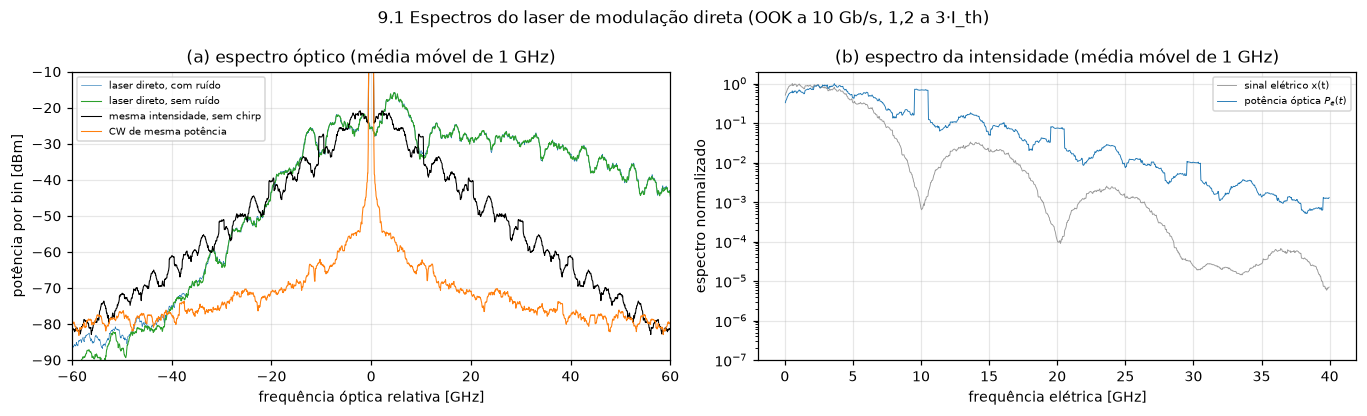

In [11]:
bits91 = np.random.default_rng(4).integers(0, 2, 256)
nrz91 = np.convolve(np.repeat(bits91.astype(float), SPS9), np.ones(30) / 30, mode="same")
grade91 = TimeGrid(1e12, nrz91.size)
x91 = Waveform(samples=nrz91.astype(complex)[None, :], grid=grade91, domain=Domain.ELECTRICAL,
               geometry=SignalGeometry(n_symbols=bits91.size, bits_per_symbol=1,
                                       samples_per_symbol=SPS9, n_pol=1),
               channel_id=0)
ctx91 = SimContext(grid=grade91, root_seed=1)
y91 = dml9(x91, ctx91).samples[0]                                         # com ruído
y91_det = dataclasses.replace(dml9, noise=False)(x91, ctx91).samples[0]   # sem ruído
pe91 = np.abs(y91_det) ** 2
sem_chirp = np.sqrt(pe91).astype(complex)                                 # mesma intensidade, sem fase
cw91 = CWLaser(CWLaserConfig(power=pe91.mean(), linewidth=1e6), F_LASER)(x91, ctx91).samples[0]
f91 = np.fft.fftshift(grade91.optical_frequency)

def suaviza(S, n=26):
    """Média móvel de n bins (26 bins = 1 GHz) na potência linear, para ler o espectro."""
    return np.convolve(S, np.ones(n) / n, mode="same")

JANELA = np.hanning(nrz91.size)

def por_bin_dbm(campo):
    """Potência por bin da FFT [dBm], com janela de Hann (a fase do laser direto não fecha
    nas bordas da janela, e sem ela o salto vaza para o espectro todo) e média móvel de 1 GHz."""
    S = np.fft.fftshift(np.abs(np.fft.fft(campo * JANELA) / campo.size) ** 2) / np.mean(JANELA ** 2)
    return 10 * np.log10(suaviza(S) + 1e-30) + 30

def banda_99(campo):
    """Largura da faixa centrada na portadora que contém 99 % da potência óptica."""
    S = np.fft.fftshift(np.abs(np.fft.fft(campo * JANELA)) ** 2)
    c = np.argmin(np.abs(f91))
    acum = [S[c - k:c + k + 1].sum() for k in range(S.size // 2)]
    k = np.argmax(np.array(acum) >= 0.99 * S.sum())
    return 2 * k * abs(f91[1] - f91[0])

fig, ax = plt.subplots(1, 2, figsize=(12.5, 3.8))
for campo, nome, cor, lw in [(y91, "laser direto, com ruído", C3[0], 0.4),
                             (y91_det, "laser direto, sem ruído", C3[2], 0.7),
                             (sem_chirp, "mesma intensidade, sem chirp", "k", 0.7),
                             (cw91, "CW de mesma potência", C3[1], 0.7)]:
    ax[0].plot(f91 / 1e9, por_bin_dbm(campo), color=cor, lw=lw, label=nome)
ax[0].set(xlim=(-60, 60), ylim=(-90, -10), xlabel="frequência óptica relativa [GHz]",
          ylabel="potência por bin [dBm]", title="(a) espectro óptico (média móvel de 1 GHz)")
ax[0].legend(fontsize=6.5, loc="upper left")
fe = grade91.freq
pos = (fe > 0) & (fe < 40e9)
X = suaviza(np.abs(np.fft.fft(nrz91 - nrz91.mean())) ** 2)
P = suaviza(np.abs(np.fft.fft(pe91 - pe91.mean())) ** 2)
ax[1].semilogy(fe[pos] / 1e9, X[pos] / X[pos].max(), color="0.6", lw=0.6, label="sinal elétrico x(t)")
ax[1].semilogy(fe[pos] / 1e9, P[pos] / P[pos].max(), color=C3[0], lw=0.6, label="potência óptica $P_e(t)$")
ax[1].set(ylim=(1e-7, 2), xlabel="frequência elétrica [GHz]", ylabel="espectro normalizado",
          title="(b) espectro da intensidade (média móvel de 1 GHz)")
ax[1].legend(fontsize=6.5)
fig.suptitle("9.1 Espectros do laser de modulação direta (OOK a 10 Gb/s, 1,2 a 3·I_th)")
fig.tight_layout()
for campo, nome in [(sem_chirp, "sem chirp"), (y91_det, "laser direto, sem ruído"),
                    (y91, "laser direto, com ruído"), (cw91, "CW")]:
    print(f"{nome}: 99 % da potência em {banda_99(campo)/1e9:.2f} GHz")

**Leitura.** (Números na saída da célula.)
- (a) Com a mesma intensidade, o campo sem chirp fica simétrico em torno da portadora, com 99 %
  da potência em ~27 GHz. A saída do laser direto ocupa ~96 GHz, 3,5 vezes mais, e é
  assimétrica: a maior parte vai para o azul (+f), com pico em ~6 GHz.
  É o chirp: o transitório nas bordas de subida (até +25 GHz) e o adiabático, que põe o bit 1
  alguns GHz acima do bit 0 (seção 9). O CW é uma linha só (1 MHz). O ruído de Langevin quase
  não muda o espectro do laser direto (as duas curvas se sobrepõem).
- (b) O sinal elétrico NRZ tem os nulos em 10, 20 e 30 GHz (múltiplos da taxa de bits). A
  potência óptica segue o sinal em baixa frequência, mas preenche os nulos e tem muito mais
  conteúdo acima de ~8 GHz: a resposta do laser não é linear em grande sinal, com os picos de
  relaxação nas bordas de subida (~10 GHz em 3·I_th, seção 5). As linhas em 10, 20 e 30 GHz
  aparecem porque subida e descida não são simétricas: sobra uma componente periódica na taxa
  de bits.
- Para o enlace, o que pesa é (a): o espectro mais largo do laser direto é o que a dispersão da
  fibra transforma em alargamento dos pulsos (notebook 01, seção 3).